 ЭТАП 1: АВТОМАТИЧЕСКАЯ ЛОКАЛИЗАЦИЯ КОРНЕЙ
Корень 1 локализован на отрезке: [-0.9400, -0.8900]
Корень 2 локализован на отрезке: [0.4100, 0.4600]


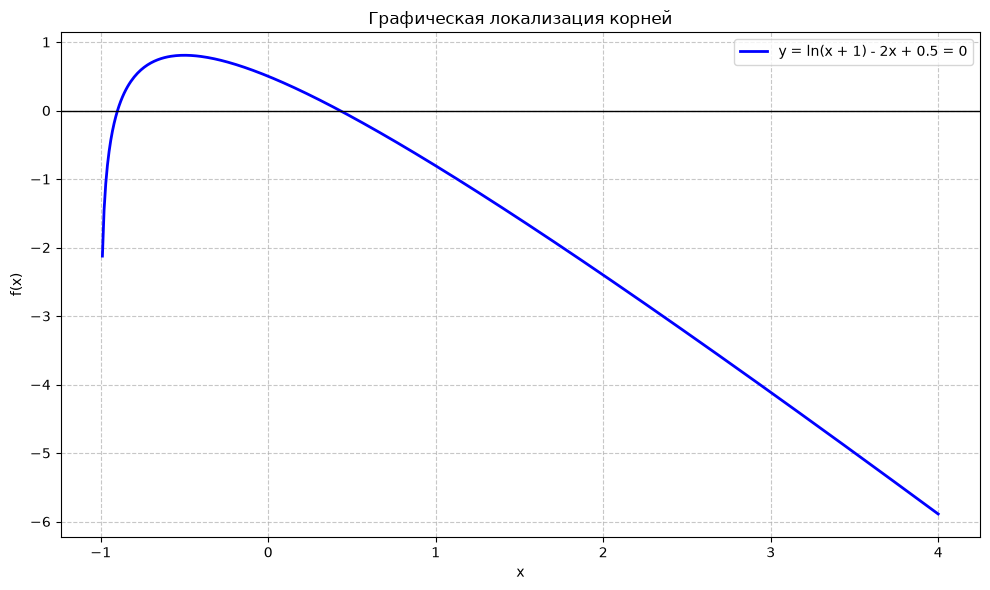


 ЭТАП 2: УТОЧНЕНИЕ КОРНЕЙ (Точность eps = 0.001)

 Обработка Корня 1 на отрезке [-0.9400, -0.8900]:
-------------------------------------------------------------------------------------
Метод                               | Итераций   | Найденный корень x*  | Невязка |f(x*)|
-------------------------------------------------------------------------------------
1. Метод Ньютона                    | 3          | -0.899680            | 2.658e-05      
2. Простые итерации (q=0.35)        | 3          | -0.899871            | 1.555e-03      
-------------------------------------------------------------------------------------

 Обработка Корня 2 на отрезке [0.4100, 0.4600]:
-------------------------------------------------------------------------------------
Метод                               | Итераций   | Найденный корень x*  | Невязка |f(x*)|
-------------------------------------------------------------------------------------
1. Метод Ньютона                    | 2          | 0.428211 

In [ ]:
import math
import os
import matplotlib.pyplot as plt


def create_default_config(filename="input.txt"):
    """Создает файл с входными данными, если он отсутствует."""

    if not os.path.exists(filename):
        with open(filename, "w", encoding="utf-8") as f:
            f.write("-0.95 3.0\n")

def read_search_interval(filename="input.txt"):
    """Считывает границы интервала из файла."""

    with open(filename, "r", encoding="utf-8") as f:
        line = f.readline().strip()
        x_min, x_max = map(float, line.split())

    return x_min, x_max


class NonlinearEquation:
    def __init__(self):

        self.name = "ln(x + 1) - 2x + 0.5 = 0"

        self.f = lambda x: math.log(x + 1.0) - 2.0 * x + 0.5
        self.df = lambda x: 1.0 / (x + 1.0) - 2.0
        self.d2f = lambda x: -1.0 / ((x + 1.0) ** 2)


def scan_for_roots(eq, x_min, x_max, step=0.05):
    """Сканирует область и находит подотрезки, где функция меняет знак."""

    intervals = []
    x_curr = x_min
    
    while x_curr < x_max:
        x_next = min(x_curr + step, x_max)
        f_curr, f_next = eq.f(x_curr), eq.f(x_next)
        
        if f_curr * f_next < 0:
            intervals.append((x_curr, x_next))
            
        x_curr = x_next

    return intervals


def plot_function(eq, x_min, x_max):
    """Строит график и подсвечивает найденные интервалы локализации."""

    n_pts = 500
    step = (x_max - x_min) / n_pts
    x_vals = [x_min + i * step for i in range(n_pts + 1)]
    y_vals = [eq.f(x) for x in x_vals]
    
    plt.figure(figsize=(9, 5))
    plt.plot(x_vals, y_vals, 'b-', linewidth=2, label=f'y = {eq.name}')
    plt.axhline(0, color='black', linewidth=1)

    plt.grid(True, linestyle='--', alpha=0.7)
    plt.title('Графическая локализация корней')
    plt.xlabel('x')
    plt.ylabel('f(x)')
    plt.legend()
    plt.tight_layout()
    plt.show()


def newton_method(eq, a, b, eps, max_iter=500):
    if eq.f(a) * eq.d2f(a) > 0:
        x0 = a
    elif eq.f(b) * eq.d2f(b) > 0:
        x0 = b
    else:
        x0 = (a + b) / 2.0

    xk = x0
    k = 0

    while k < max_iter:
        fxk = eq.f(xk)
        dfxk = eq.df(xk)
        
        if abs(dfxk) < 1e-15:
            break
            
        delta = -fxk / dfxk
        xk_next = xk + delta
        
        if abs(delta) <= eps or abs(fxk) <= eps:
            return xk_next, k + 1
            
        xk = xk_next
        k += 1

    return xk, max_iter


def simple_iteration_method(eq, a, b, eps, max_iter=500):
    dfa, dfb = eq.df(a), eq.df(b)
    lam = 2.0 / (dfa + dfb)
    
    phi = lambda x: x - lam * eq.f(x)
    dphi = lambda x: 1.0 - lam * eq.df(x)
    
    q = max(abs(dphi(a)), abs(dphi(b)))
    
    xk = (a + b) / 2.0
    k = 0

    while k < max_iter:
        xk_next = phi(xk)
        diff = abs(xk_next - xk)
        
        eps_adj = eps if q <= 0.5 else ((1.0 - q) / q) * eps
        
        if diff <= eps_adj:
            return xk_next, k + 1, q
            
        xk = xk_next
        k += 1
    
    return xk, max_iter, q


def run_solver():
    create_default_config()
    x_min, x_max = read_search_interval()
    
    eq = NonlinearEquation()
    eps = 0.001
    
    print("=" * 80)
    print(" ЭТАП 1: ЛОКАЛИЗАЦИЯ И ЧТЕНИЕ ДАННЫХ ИЗ ФАЙЛА")
    print("=" * 80)
    print(f"Область поиска успешно считана из файла: [{x_min}, {x_max}]")
    
    intervals = scan_for_roots(eq, x_min, x_max)
    
    if not intervals:
        print("Корни на заданном отрезке не найдены.")
        return
        
    for idx, (a, b) in enumerate(intervals):
        print(f"Корень {idx + 1} локализован на отрезке: [{a:.4f}, {b:.4f}]")
        
    plot_function(eq, x_min, x_max)
    
    print("\n" + "=" * 80)
    print(f" ЭТАП 2: УТОЧНЕНИЕ КОРНЕЙ (Точность eps = {eps})")
    print("=" * 80)
    
    for idx, (a, b) in enumerate(intervals):
        print(f"\n Обработка Корня {idx + 1} на отрезке [{a:.4f}, {b:.4f}]:")
        
        x_newt, k_newt = newton_method(eq, a, b, eps)
        x_iter, k_iter, q_val = simple_iteration_method(eq, a, b, eps)
        
        print("-" * 80)
        print(f"{'Метод':<28} | {'Итераций':<9} | {'Корень x*':<13} | {'Невязка |f(x*)|':<15}")
        print("-" * 80)
        print(f"{'Метод Ньютона':<28} | {k_newt:<9} | {x_newt:<13.6f} | {abs(eq.f(x_newt)):<15.3e}")
        print(f"{f'Простые итерации (q={q_val:.2f})':<28} | {k_iter:<9} | {x_iter:<13.6f} | {abs(eq.f(x_iter)):<15.3e}")
        print("-" * 80)


if __name__ == '__main__':
    run_solver()